<a href="https://colab.research.google.com/github/Salih-kk/ml-projects/blob/main/california_housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

(17000, 9)
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
dtype: int64
(16186, 9)


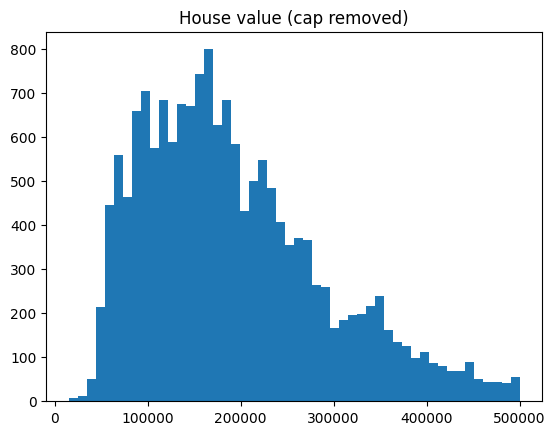

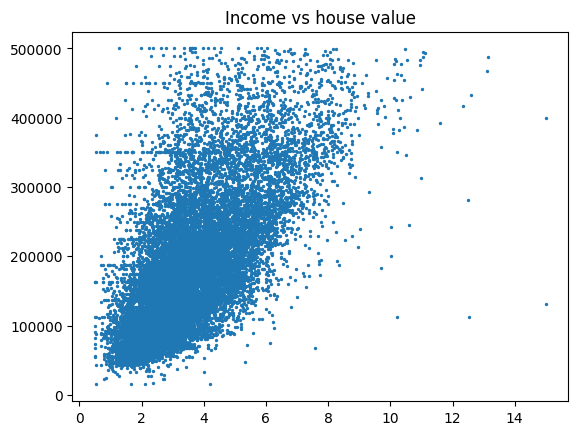

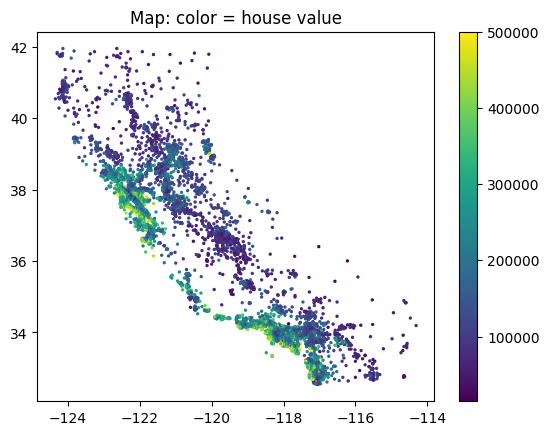

Linear R2: 0.6068872088444508
Random Forest R2: 0.7913256043941191
Average error ($): 29487.101037677578


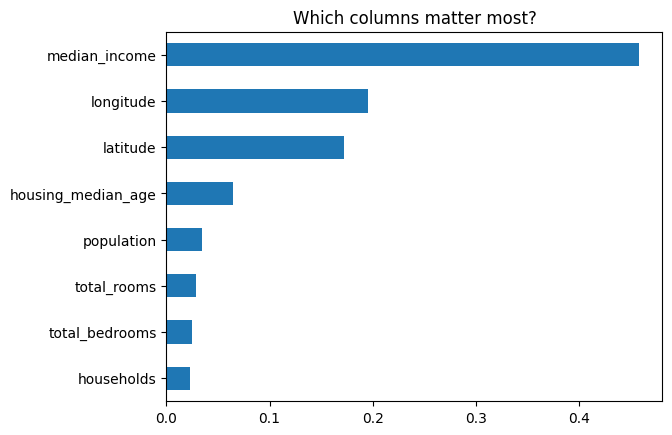

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/sample_data/california_housing_train.csv")
print(df.shape)
print(df.isna().sum())          # missing values per column

# values above 500000 were capped at 500001, so remove those rows
df = df[df["median_house_value"] != 500001]
print(df.shape)

plt.hist(df["median_house_value"], bins=50)
plt.title("House value (cap removed)")
plt.show()

plt.scatter(df["median_income"], df["median_house_value"], s=2)
plt.title("Income vs house value")
plt.show()

plt.scatter(df["longitude"], df["latitude"], c=df["median_house_value"], s=2)
plt.colorbar()
plt.title("Map: color = house value")
plt.show()
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

X = df.drop(columns=["median_house_value"])   # the clues
y = df["median_house_value"]                  # the answer to predict

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lin = LinearRegression().fit(X_train, y_train)
print("Linear R2:", lin.score(X_test, y_test))

rf = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)
print("Random Forest R2:", rf.score(X_test, y_test))

pred = rf.predict(X_test)
print("Average error ($):", abs(pred - y_test).mean())
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importance.plot(kind="barh")
plt.title("Which columns matter most?")
plt.show()